In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import torch
print('GPU available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU name:', torch.cuda.get_device_name(0))

import os
for root, dirs, files in os.walk('/kaggle/input'):
    print(root, '->', len(files), 'files')
    for f in files[:5]:
        print('   ', f)


GPU available: False
/kaggle/input -> 0 files
/kaggle/input/datasets -> 0 files
/kaggle/input/datasets/simuletic -> 0 files
/kaggle/input/datasets/simuletic/cctv-weapon-dataset -> 1 files
    evaluation.mp4
/kaggle/input/datasets/simuletic/cctv-weapon-dataset/Dataset -> 1 files
    annotation_sample.csv
/kaggle/input/datasets/simuletic/cctv-weapon-dataset/Dataset/images -> 141 files
    Scene1_1.png
    Scene1_10.png
    Scene1_11.png
    Scene1_12.png
    Scene1_2.png
/kaggle/input/datasets/simuletic/cctv-weapon-dataset/Dataset/labels -> 141 files
    Scene1_1.txt
    Scene1_10.txt
    Scene1_11.txt
    Scene1_12.txt
    Scene1_2.txt


In [1]:
import torch
print('GPU available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU name:', torch.cuda.get_device_name(0))


GPU available: True
GPU name: Tesla T4


In [2]:
import os, glob
base = '/kaggle/input/datasets/simuletic/cctv-weapon-dataset'
print('--- dataset root ---')
for item in sorted(os.listdir(base)):
    p = os.path.join(base, item)
    if os.path.isdir(p):
        print('DIR :', item, '->', len(os.listdir(p)), 'files')
    else:
        print('FILE:', item)

imgs = glob.glob(base + '/**/*.png', recursive=True)
lbls = glob.glob(base + '/**/*.txt', recursive=True)
print('Total PNG images:', len(imgs))
print('Total TXT labels:', len(lbls))
print('First image:', imgs[0] if imgs else None)
print('First label:', lbls[0] if lbls else None)
if lbls:
    print('--- sample label ---')
    print(open(lbls[0]).read())
print('data.yaml exists:', os.path.exists(base + '/data.yaml'))

csv_path = base + '/annotation_sample.csv'
print('--- annotation_sample.csv (first 5 lines) ---')
with open(csv_path) as f:
    for i, line in enumerate(f):
        print(line.strip())
        if i >= 4:
            break


--- dataset root ---
DIR : Dataset -> 3 files
FILE: evaluation.mp4
Total PNG images: 141
Total TXT labels: 141
First image: /kaggle/input/datasets/simuletic/cctv-weapon-dataset/Dataset/images/Scene1_1.png
First label: /kaggle/input/datasets/simuletic/cctv-weapon-dataset/Dataset/labels/Scene1_1.txt
--- sample label ---
0 0.688909 0.486803 0.114789 0.317230
1 0.642249 0.448207 0.080718 0.086321
data.yaml exists: False
--- annotation_sample.csv (first 5 lines) ---


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/datasets/simuletic/cctv-weapon-dataset/annotation_sample.csv'

In [4]:
import os, glob, shutil, random
from collections import Counter

base = '/kaggle/input/datasets/simuletic/cctv-weapon-dataset'
imgs = sorted(glob.glob(base + '/**/*.png', recursive=True))
lbls = sorted(glob.glob(base + '/**/*.txt', recursive=True))
img_dir = os.path.dirname(imgs[0])
lbl_dir = os.path.dirname(lbls[0])
print('Images folder:', img_dir)
print('Labels folder:', lbl_dir)
print('Images:', len(imgs), '| Labels:', len(lbls))

img_names = {os.path.splitext(os.path.basename(p))[0] for p in imgs}
lbl_names = {os.path.splitext(os.path.basename(p))[0] for p in lbls}
print('Images without label:', len(img_names - lbl_names))
print('Labels without image:', len(lbl_names - img_names))

cls_count = Counter()
for lp in lbls:
    for line in open(lp):
        parts = line.strip().split()
        if parts:
            cls_count[int(parts[0])] += 1
print('Boxes per class:', dict(cls_count))

random.seed(42)
names = sorted(img_names)
random.shuffle(names)
n = len(names)
n_train = int(n * 0.80)
n_val = int(n * 0.15)
train_names = names[:n_train]
val_names = names[n_train:n_train + n_val]
test_names = names[n_train + n_val:]
print('Split -> train:', len(train_names), 'val:', len(val_names), 'test:', len(test_names))

out = '/kaggle/working/weapon_data'
for split in ['train', 'val', 'test']:
    os.makedirs(f'{out}/images/{split}', exist_ok=True)
    os.makedirs(f'{out}/labels/{split}', exist_ok=True)

def copy_split(split_names, split):
    for name in split_names:
        shutil.copy(os.path.join(img_dir, name + '.png'), f'{out}/images/{split}/{name}.png')
        shutil.copy(os.path.join(lbl_dir, name + '.txt'), f'{out}/labels/{split}/{name}.txt')

copy_split(train_names, 'train')
copy_split(val_names, 'val')
copy_split(test_names, 'test')

yaml_text = f"""path: {out}
train: images/train
val: images/val
test: images/test
nc: 2
names: ['person', 'weapon']
"""
with open(f'{out}/data.yaml', 'w') as f:
    f.write(yaml_text)
print('data.yaml written:')
print(open(f'{out}/data.yaml').read())


Images folder: /kaggle/input/datasets/simuletic/cctv-weapon-dataset/Dataset/images
Labels folder: /kaggle/input/datasets/simuletic/cctv-weapon-dataset/Dataset/labels
Images: 141 | Labels: 141
Images without label: 0
Labels without image: 0
Boxes per class: {0: 139, 1: 130}
Split -> train: 112 val: 21 test: 8
data.yaml written:
path: /kaggle/working/weapon_data
train: images/train
val: images/val
test: images/test
nc: 2
names: ['person', 'weapon']



In [5]:
!pip install -q ultralytics

from ultralytics import YOLO

model = YOLO('yolov10n.pt')
model.train(
    data='/kaggle/working/weapon_data/data.yaml',
    epochs=130,
    imgsz=640,
    batch=16,
    lr0=0.001,
    optimizer='AdamW',
    device=0,
    project='/kaggle/working/runs',
    name='weapon_yolov10n',
)
print('Training done!')
print('Best weights: /kaggle/working/runs/detect/weapon_yolov10n/weights/best.pt')


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/weapon_data/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=130, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fract

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/130      2.94G      1.744      4.647      1.308         63        640: 100% ━━━━━━━━━━━━ 7/7 6.0it/s 1.2s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.2it/s 0.8s
                   all         21         41     0.0783      0.407      0.226     0.0841

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/130      2.94G      1.987      3.826      1.501         56        640: 100% ━━━━━━━━━━━━ 7/7 6.6it/s 1.1s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.1it/s 0.9s
                   all         21         41      0.336      0.286      0.331      0.124

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      4/130      2.94G      2.096      3.489      1.517         55        640: 100% ━━━━━━━━━━━━ 7/7 6.8it/s 1.0s0.2s
                 Class     Images  Instances      Box(P     

In [6]:
from ultralytics import YOLO
from IPython.display import Image, display
import glob, pandas as pd

model = YOLO('/kaggle/working/runs/detect/weapon_yolov10n/weights/best.pt')
results = model.predict('/kaggle/working/weapon_data/images/test', save=True, conf=0.25)

for r in results[:3]:
    dets = [(model.names[int(c)], round(float(s), 2)) for c, s in zip(r.boxes.cls, r.boxes.conf)]
    print(r.path.split('/')[-1], '->', dets)

df = pd.read_csv('/kaggle/working/runs/detect/weapon_yolov10n/results.csv')
print(df[['epoch', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)']].tail(3).to_string(index=False))

pred = sorted(glob.glob('/kaggle/working/runs/detect/predict/*.jpg'))
print('Predicted images:', len(pred))
display(Image(pred[0], width=640))


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/runs/detect/weapon_yolov10n/weights/best.pt'

Found best.pt: /kaggle/working/runs/weapon_yolov10n/weights/best.pt

image 1/8 /kaggle/working/weapon_data/images/test/Scene1_4.png: 640x640 (no detections), 10.0ms
image 2/8 /kaggle/working/weapon_data/images/test/Scene2_19.png: 640x640 1 person, 1 weapon, 10.1ms
image 3/8 /kaggle/working/weapon_data/images/test/Scene2_22.png: 640x640 1 person, 1 weapon, 10.0ms
image 4/8 /kaggle/working/weapon_data/images/test/Scene2_24.png: 640x640 1 person, 1 weapon, 10.0ms
image 5/8 /kaggle/working/weapon_data/images/test/Scene2_30.png: 640x640 1 person, 1 weapon, 10.0ms
image 6/8 /kaggle/working/weapon_data/images/test/Scene3_20.png: 640x448 1 person, 1 weapon, 44.7ms
image 7/8 /kaggle/working/weapon_data/images/test/Scene3_25.png: 640x448 1 person, 1 weapon, 7.9ms
image 8/8 /kaggle/working/weapon_data/images/test/Scene3_4.png: 640x448 1 person, 1 weapon, 8.0ms
Speed: 2.8ms preprocess, 13.8ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 448)
Results saved to /kaggle/working/runs/det

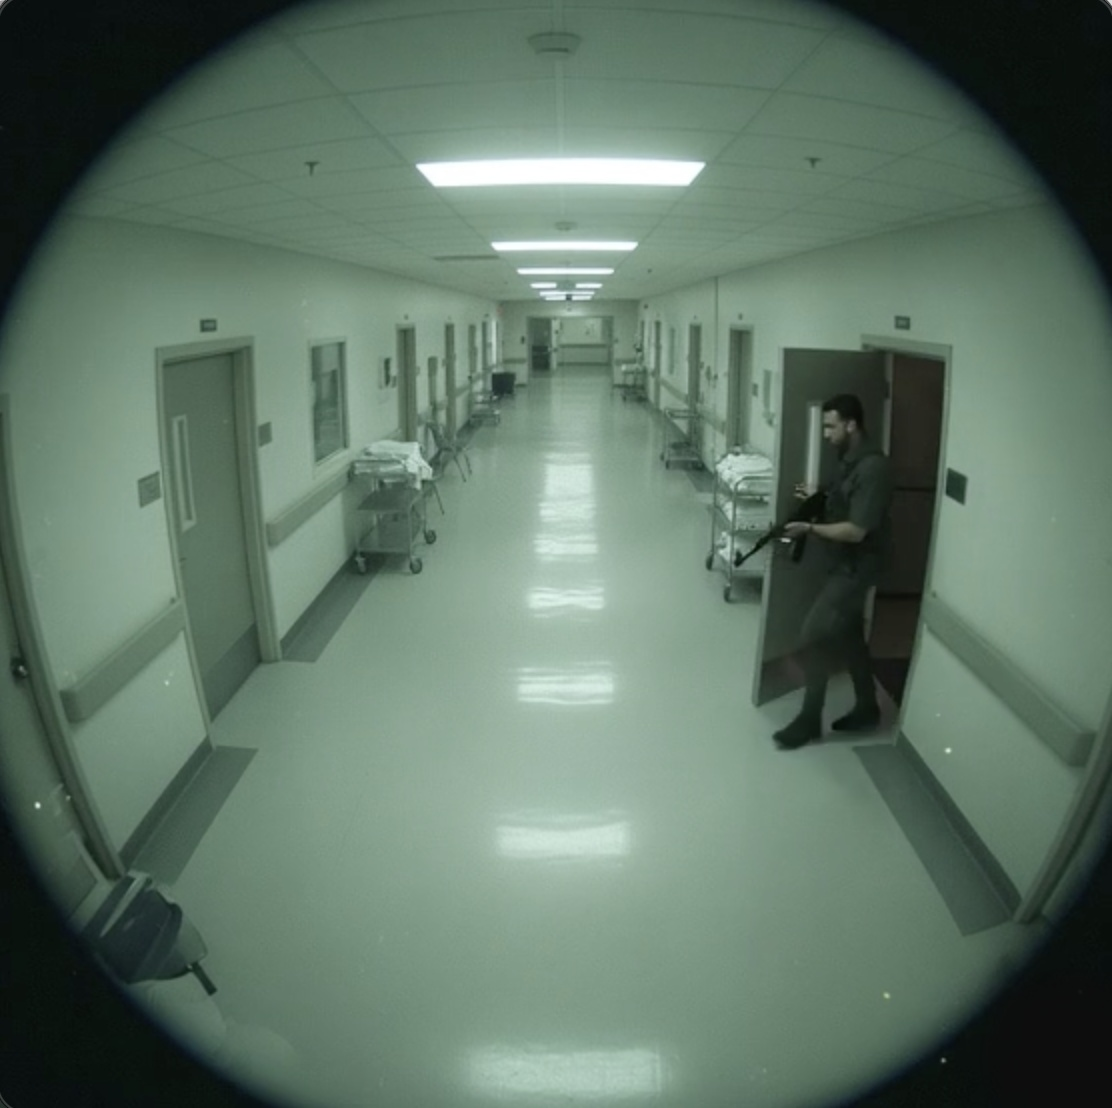

In [7]:
from ultralytics import YOLO
from IPython.display import Image, display
import glob, pandas as pd

best = glob.glob('/kaggle/working/runs/**/best.pt', recursive=True)[0]
print('Found best.pt:', best)
run_dir = best.split('/weights/')[0]

model = YOLO(best)
results = model.predict('/kaggle/working/weapon_data/images/test', save=True, conf=0.25)

for r in results[:3]:
    dets = [(model.names[int(c)], round(float(s), 2)) for c, s in zip(r.boxes.cls, r.boxes.conf)]
    print(r.path.split('/')[-1], '->', dets)

df = pd.read_csv(run_dir + '/results.csv')
print(df[['epoch', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)']].tail(3).to_string(index=False))

pred = sorted(glob.glob('/kaggle/working/runs/**/predict/*.jpg', recursive=True))
print('Predicted images:', len(pred))
if pred:
    display(Image(pred[0], width=640))
